# P3.03 — Robustness, placebos and power of the IMI capitalisation estimate

**Questions:** RQ7.4 and M3. `p3_02` gives the main event study. Here: does the answer change with the sample and
the definition of treatment, is a rent outcome feasible, and what size of effect could the design have detected?

**Variants (dose version, per 0.01 pp of cut; all run with the stacked regression):**
- *Cut size at least 0.03 pp*: the larger cuts only.
- *Without the 2020 wave*: 31 isolated cuts in the pandemic year, almost half the treated sample.
- *Only the 2020 wave*.
- *Controls above the floor*: 98 of the never-changing municipalities sit at 0.30% and cannot cut; keep controls
  that could have.
- *Without parish-link municipalities*: those that show the "Taxas por freguesia" link in any year from 2013,
  where the municipal rate may not be the effective one.
- *Stable family deduction*: drop units whose family-deduction (IMI Familiar) status changes inside their window.
- *Without Lisboa and Porto*, *one pre-period year*, and *price-to-income as the outcome* (the affordability
  version of the question; income is not affected by the rate).

The 2016 wave (87 cuts) is outside the sample by construction: prices start in 2016, so it has no pre-period.

In [1]:
import pandas as pd
import yaml

from pthousing.analysis import causal
from pthousing.config import SCENARIOS_YAML
from pthousing.data import build_panel
from pthousing.viz import charts, style

style.apply_style()
frame = causal.build_frame(build_panel.read("panel_municipality_year"))
mainland = frame[frame["territory"] == "continente"]
LISBOA_PORTO = {"1106", "1312"}

bench = yaml.safe_load(SCENARIOS_YAML.read_text(encoding="utf-8"))["imi_capitalisation_benchmark"]
tv, dr = bench["tax_value_ratio"], bench["discount_rate"]
full = (
    causal.full_capitalisation_pct(0.01, tv["low"], dr["high"]),
    causal.full_capitalisation_pct(0.01, tv["mid"], dr["mid"]),
    causal.full_capitalisation_pct(0.01, tv["high"], dr["low"]),
)

In [2]:
specs = {
    "Main": {},
    "Cut size at least 0.03 pp": dict(min_cut_pp=0.03),
    "Without the 2020 wave": dict(exclude_events={2020}),
    "Only the 2020 wave": dict(event_years=(2020, 2020)),
    "Controls above the floor": dict(control_min_rate_pct=causal.RATE_FLOOR_PCT),
    "Without parish-link municipalities": dict(sample={"parish_free": True}),
    "Stable family deduction": dict(sample={"stable_deduction": True}),
    "Without Lisboa and Porto": dict(drop_munis=LISBOA_PORTO),
    "Price-to-income as outcome": dict(outcome="log_pti"),
}
rows = []
for label, kw in specs.items():
    es = causal.event_study(causal.build_stacks(mainland, **kw), dose=True)
    t = es.table.assign(
        spec=label, n_treated=es.n_treated, n_controls=es.n_controls, pretrend_p=es.pretrend_p
    )
    rows.append(t)
ladder = pd.concat(rows, ignore_index=True)
for col in ("coef", "se", "ci_low", "ci_high"):
    ladder[col] = 100 * ladder[col]
style.save_table(ladder.round(3), "p3", "robustness_event_study")
ladder.query("k in [-2, 1, 2]").pivot(
    index="spec", columns="k", values=["coef", "se", "pretrend_p"]
).reindex(specs).round(2)

coef                se              \
k                                     -2     1     2    -2     1     2   
spec                                                                     
Main                               -1.51 -0.24 -0.81  0.67  0.81  1.39   
Cut size at least 0.03 pp          -1.53 -0.47 -1.15  0.73  0.80  1.41   
Without the 2020 wave              -1.03 -0.81  0.31  0.82  0.96  1.48   
Only the 2020 wave                 -2.31  0.70 -2.66  1.06  1.78  2.18   
Controls above the floor           -1.38 -0.87 -1.90  1.05  1.43  2.46   
Without parish-link municipalities -2.18 -0.56 -1.49  1.07  1.23  1.83   
Stable family deduction            -1.57 -0.37 -0.80  0.72  0.82  1.39   
Without Lisboa and Porto           -1.51 -0.26 -0.86  0.67  0.81  1.39   
Price-to-income as outcome         -1.89 -0.35 -1.61  0.74  1.00  1.60   

                                   pretrend_p              
k                                          -2     1     2  
spec                                                       
Main                                     0.02  0.02  0.02  
Cut size at least 0.03 pp                0.04  0.04  0.04  
Without the 2020 wave                    0.21  0.21  0.21  
Only the 2020 wave                       0.03  0.03  0.03  
Controls above the floor                 0.19  0.19  0.19  
Without parish-link municipalities       0.04  0.04  0.04  
Stable family deduction                  0.03  0.03  0.03  
Without Lisboa and Porto                 0.02  0.02  0.02  
Price-to-income as outcome               0.01  0.01  0.01

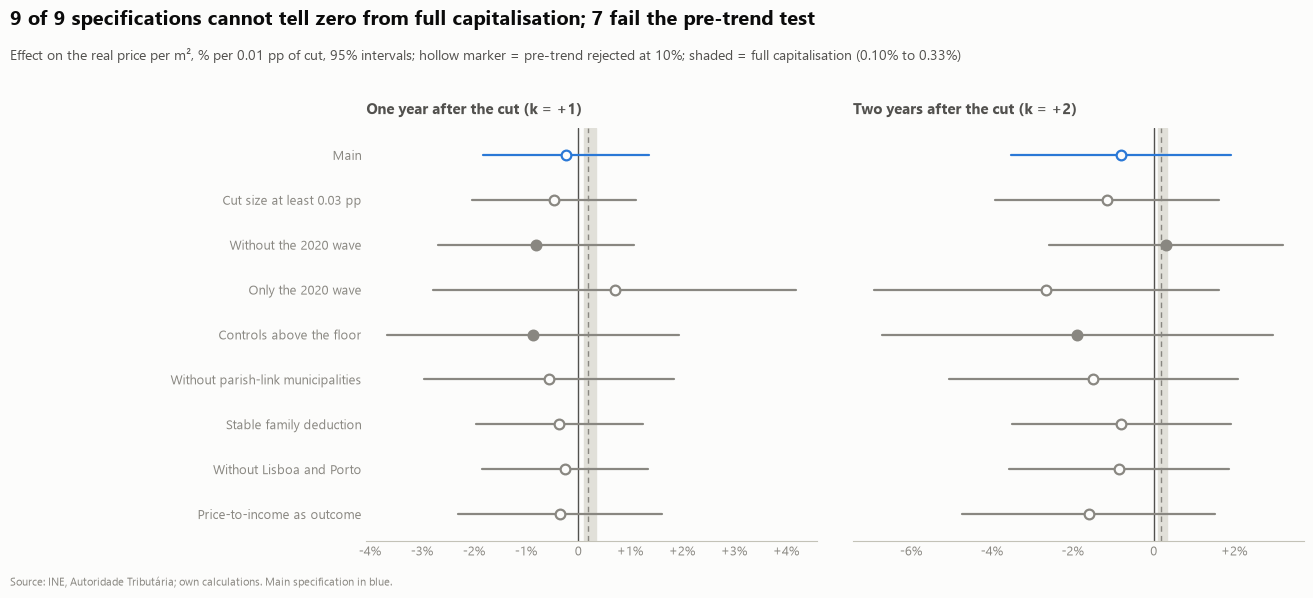

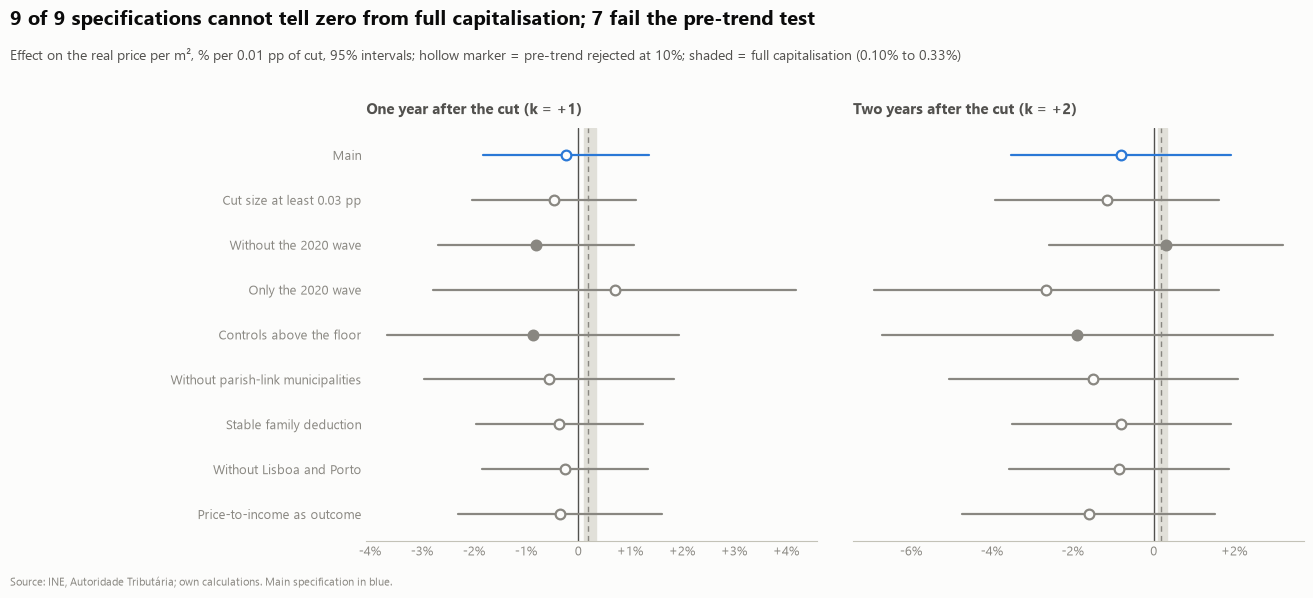

In [3]:
fig = charts.robustness_ladder(ladder, "Main", full)
style.save_fig(fig, "p3", "robustness_ladder")
fig

## Placebo and a rent outcome
Rent is a placebo-type outcome: if landlords do not pass the tax on, rents should not move. INE's municipal
rents start in 2020 (and only where at least 33 leases are registered), so the window shrinks to one year before
and two after, leaving events in 2021 and 2022 only.

In [4]:
rent = causal.build_stacks(mainland, outcome="log_rent_real", pre=1, post=2)
if rent["treated"].any():
    rent_es = causal.event_study(rent, dose=True)
    rent_table = rent_es.table.assign(n_treated=rent_es.n_treated, n_controls=rent_es.n_controls)
    for col in ("coef", "se", "ci_low", "ci_high"):
        rent_table[col] = 100 * rent_table[col]
    style.save_table(rent_table.round(3), "p3", "rent_event_study")
    print(rent_table.round(2).to_string(index=False))
else:
    print("no isolated cut has rents in its window")

 k  coef   se  ci_low  ci_high    p  n_treated  n_controls
 0  0.28 3.13   -5.89     6.45 0.93          5         150
 1 -4.00 3.56  -11.00     3.00 0.26          5         150
 2 -6.44 5.52  -17.31     4.44 0.25          5         150


## Power
The minimum detectable effect at 5% significance and 80% power is 2.8 standard errors. Compare it with the
benchmark of a fully capitalised cut.

In [5]:
main = ladder[ladder["spec"] == "Main"].set_index("k")
power = pd.DataFrame(
    {
        "k": [1, 2],
        "se_pct_per_0.01pp": [main.loc[1, "se"], main.loc[2, "se"]],
        "min_detectable_pct": [2.8 * main.loc[1, "se"], 2.8 * main.loc[2, "se"]],
        "full_capitalisation_mid_pct": full[1],
    }
)
power["detectable_over_benchmark"] = (
    power["min_detectable_pct"] / power["full_capitalisation_mid_pct"]
)
style.save_table(power.round(3), "p3", "power")
power.round(2)

,k,se_pct_per_0.01pp,min_detectable_pct,full_capitalisation_mid_pct,detectable_over_benchmark
0,1,0.81,2.27,0.19,12.13
1,2,1.39,3.90,0.19,20.77


**Reading.** See `reports/p3_policy.md` for the interpretation. In short: the event study can only detect effects
many times larger than full capitalisation, so it can neither confirm nor rule out the plausible range, and
the pre-trend test fails in most specifications.